In [1]:
# Import Necessary Libraries

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

print("Libraries imported successfully")

Libraries imported successfully


In [2]:
# Load the Breast Cancer Dataset

df = pd.read_csv("/home/aditya/Downloads/data.csv")

print("Dataset loaded successfully")
print(df.head())
print("\nDataset Shape:", df.shape)

Dataset loaded successfully
         id diagnosis  radius_mean  texture_mean  perimeter_mean  area_mean  \
0    842302         M        17.99         10.38          122.80     1001.0   
1    842517         M        20.57         17.77          132.90     1326.0   
2  84300903         M        19.69         21.25          130.00     1203.0   
3  84348301         M        11.42         20.38           77.58      386.1   
4  84358402         M        20.29         14.34          135.10     1297.0   

   smoothness_mean  compactness_mean  concavity_mean  concave points_mean  \
0          0.11840           0.27760          0.3001              0.14710   
1          0.08474           0.07864          0.0869              0.07017   
2          0.10960           0.15990          0.1974              0.12790   
3          0.14250           0.28390          0.2414              0.10520   
4          0.10030           0.13280          0.1980              0.10430   

   ...  texture_worst  perimeter_w

In [3]:
# Prepare Input and Output Data

X = df.drop(
    columns=['id', 'diagnosis', 'Unnamed: 32'],
    errors='ignore'
)

y = df['diagnosis'].map({'M': 1, 'B': 0})

print("Input Shape:", X.shape)
print("Output Shape:", y.shape)
print("Data prepared successfully")

Input Shape: (569, 30)
Output Shape: (569,)
Data prepared successfully


In [4]:
# Split Dataset into Training and Testing Sets

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training Data Shape:", X_train.shape)
print("Testing Data Shape:", X_test.shape)

Training Data Shape: (455, 30)
Testing Data Shape: (114, 30)


In [5]:
# Normalize Input Data

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Data normalization completed successfully")

Data normalization completed successfully


In [6]:
# Define Classification Algorithms

from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier
from sklearn.naive_bayes import GaussianNB

models = {
    'Logistic Regression': LogisticRegression(max_iter=1000),
    'K-Nearest Neighbors': KNeighborsClassifier(n_neighbors=5),
    'Support Vector Machine': SVC(),
    'Decision Tree': DecisionTreeClassifier(random_state=42),
    'Random Forest': RandomForestClassifier(n_estimators=100, random_state=42),
    'AdaBoost': AdaBoostClassifier(n_estimators=50, random_state=42),
    'Naive Bayes': GaussianNB()
}

print("Classification algorithms defined successfully")

Classification algorithms defined successfully


In [7]:
# Train and Evaluate Classification Algorithms

results = []

for name, model in models.items():

    if name in ['Decision Tree', 'Random Forest', 'AdaBoost', 'Naive Bayes']:
        model.fit(X_train, y_train)
        y_pred = model.predict(X_test)
    else:
        model.fit(X_train_scaled, y_train)
        y_pred = model.predict(X_test_scaled)

    results.append({
        'Algorithm': name,
        'Accuracy': accuracy_score(y_test, y_pred),
        'Precision': precision_score(y_test, y_pred, zero_division=0),
        'Recall': recall_score(y_test, y_pred, zero_division=0),
        'F1-Score': f1_score(y_test, y_pred, zero_division=0)
    })

print("All classification algorithms trained and evaluated successfully")

All classification algorithms trained and evaluated successfully


In [8]:
# Compare Classification Algorithms

results_df = pd.DataFrame(results)

print("Classification Algorithm Comparison")
print("-----------------------------------")
print(results_df.round(4).to_string(index=False))

Classification Algorithm Comparison
-----------------------------------
             Algorithm  Accuracy  Precision  Recall  F1-Score
   Logistic Regression    0.9649     0.9750  0.9286    0.9512
   K-Nearest Neighbors    0.9561     0.9744  0.9048    0.9383
Support Vector Machine    0.9737     1.0000  0.9286    0.9630
         Decision Tree    0.9298     0.9048  0.9048    0.9048
         Random Forest    0.9737     1.0000  0.9286    0.9630
              AdaBoost    0.9825     1.0000  0.9524    0.9756
           Naive Bayes    0.9386     1.0000  0.8333    0.9091


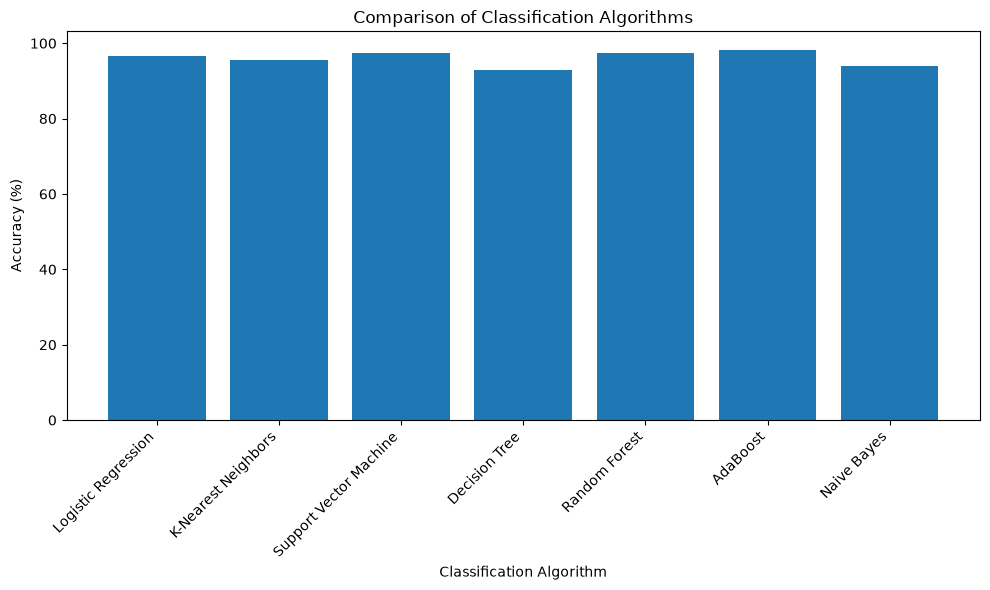

In [9]:
# Plot Accuracy of Classification Algorithms

plt.figure(figsize=(10, 6))

plt.bar(
    results_df['Algorithm'],
    results_df['Accuracy'] * 100
)

plt.xlabel('Classification Algorithm')
plt.ylabel('Accuracy (%)')
plt.title('Comparison of Classification Algorithms')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

In [10]:
# Identify the Best Performing Algorithm

best_model = results_df.loc[
    results_df['Accuracy'].idxmax()
]

print("Best Performing Algorithm:", best_model['Algorithm'])
print("Accuracy:", round(best_model['Accuracy'] * 100, 2), "%")
print("Precision:", round(best_model['Precision'], 4))
print("Recall:", round(best_model['Recall'], 4))
print("F1-Score:", round(best_model['F1-Score'], 4))

Best Performing Algorithm: AdaBoost
Accuracy: 98.25 %
Precision: 1.0
Recall: 0.9524
F1-Score: 0.9756
